In [1]:
pip install yfinance


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt # ดาวน์โหลดข้อมูล Apple Stock
df = yf.download('AAPL',start='2023-01-01', end='2024-01-01')

/Users/napat/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
[*********************100%***********************]  1 of 1 completed


Price            Close        High         Low        Open     Volume
Ticker            AAPL        AAPL        AAPL        AAPL       AAPL
Date                                                                 
2023-01-03  122.876747  128.604505  121.992528  127.995383  112117500
2023-01-04  124.144112  126.403781  122.886559  124.664816   89113600
2023-01-05  122.827629  125.529405  122.572194  124.900628   80962700
2023-01-06  127.346954  128.005203  122.699905  123.800267   87754700
2023-01-09  127.867691  131.070533  127.612256  128.182087   70790800

จานวนวันซื้อขาย: 250

ราคาเปิดเฉลี่ย: $169.76
ราคาปิด เฉลี่ย: $170.05
ราคาสูงสุด:$197.22
ราคาต ่าสุด: $121.99

ผลตอบแทนเฉลี่ย:0.183%
ความเบี่ยงเบนมาตรฐาน:1.257%

ปริมาณการซื้อขาย เฉลี่ย:59,223,548


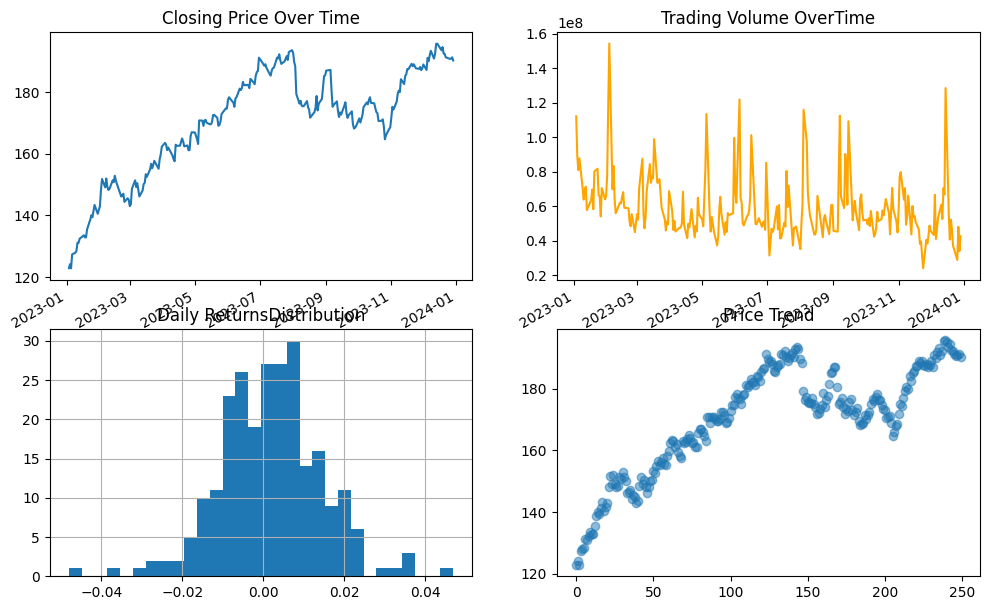

In [3]:
# 1. ตรวจสอบข้อมูล
print(df.head())
print(f'\nจานวนวันซื้อขาย: {len(df)}')
# 2. สถิติราคา
print(f'\nราคาเปิดเฉลี่ย: ${df["Open"].mean().mean():.2f}')
print(f'ราคาปิด เฉลี่ย: ${df["Close"].mean().mean():.2f}')
df.columns = df.columns.get_level_values(0)
print(f'ราคาสูงสุด:${df["High"].max():.2f}')
print(f'ราคาต ่าสุด: ${df["Low"].min():.2f}')
# 3. ความผันผวน
df['Daily_Return'] = df['Close'].pct_change()
print(f'\nผลตอบแทนเฉลี่ย:{df["Daily_Return"].mean()*100:.3f}%')
print(f'ความเบี่ยงเบนมาตรฐาน:{df["Daily_Return"].std()*100:.3f}%')
# 4. ปริมาณการซื้อขาย
print(f'\nปริมาณการซื้อขาย เฉลี่ย:{df["Volume"].mean():,.0f}')
# 5. กราฟแสดง
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
df['Close'].plot(ax=axes[0, 0])
axes[0, 0].set_title('Closing Price Over Time')
df['Volume'].plot(ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Trading Volume OverTime')
df['Daily_Return'].hist(bins=30, ax=axes[1, 0])
axes[1, 0].set_title('Daily ReturnsDistribution')
axes[1, 1].scatter(range(len(df)), df['Close'], alpha=0.5)
axes[1,1].set_title('Price Trend')
plt.show()